# Predicting Irrigation Need - Sulama İhtiyacı Tahmini

Bu projede Kaggle Playground Series S6E4 yarışmasındaki toprak, hava durumu ve tarla bilgilerinden bir tarlanın sulama ihtiyacını tahmin edeceğiz.
Bu bir sınıflandırma problemidir ve başarı ölçütü balanced accuracy'dir.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import joblib
import warnings
warnings.filterwarnings('ignore')

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import balanced_accuracy_score, classification_report, confusion_matrix

In [3]:
train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')

In [4]:
train.shape, test.shape

((630000, 21), (270000, 20))

In [5]:
train.head()

,id,Soil_Type,Soil_pH,Soil_Moisture,Organic_Carbon,Electrical_Conductivity,Temperature_C,Humidity,Rainfall_mm,Sunlight_Hours,...,Crop_Type,Crop_Growth_Stage,Season,Irrigation_Type,Water_Source,Field_Area_hectare,Mulching_Used,Previous_Irrigation_mm,Region,Irrigation_Need
0,0,Loamy,4.92,32.58,1.01,3.05,15.01,50.61,725.99,5.90,...,Sugarcane,Sowing,Zaid,Drip,Rainwater,0.82,No,112.16,East,Low
1,1,Clay,7.08,56.61,0.44,2.00,22.92,67.86,985.66,6.98,...,Wheat,Vegetative,Kharif,Rainfed,River,5.27,Yes,47.16,South,Low
2,2,Clay,5.69,27.71,0.81,2.83,26.97,92.22,2201.70,6.05,...,Rice,Vegetative,Kharif,Sprinkler,Reservoir,8.24,Yes,110.38,North,Low
3,3,Sandy,5.65,13.32,1.33,0.87,13.32,61.57,1357.33,9.12,...,Wheat,Flowering,Kharif,Canal,River,8.32,Yes,53.85,South,Medium
4,4,Clay,7.96,59.14,0.38,0.96,20.22,91.11,1538.20,6.95,...,Wheat,Sowing,Rabi,Canal,River,7.37,No,93.19,South,Low


In [6]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 630000 entries, 0 to 629999
Data columns (total 21 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   id                       630000 non-null  int64  
 1   Soil_Type                630000 non-null  object 
 2   Soil_pH                  630000 non-null  float64
 3   Soil_Moisture            630000 non-null  float64
 4   Organic_Carbon           630000 non-null  float64
 5   Electrical_Conductivity  630000 non-null  float64
 6   Temperature_C            630000 non-null  float64
 7   Humidity                 630000 non-null  float64
 8   Rainfall_mm              630000 non-null  float64
 9   Sunlight_Hours           630000 non-null  float64
 10  Wind_Speed_kmh           630000 non-null  float64
 11  Crop_Type                630000 non-null  object 
 12  Crop_Growth_Stage        630000 non-null  object 
 13  Season                   630000 non-null  object 
 14  Irri

In [7]:
train.describe()

,id,Soil_pH,Soil_Moisture,Organic_Carbon,Electrical_Conductivity,Temperature_C,Humidity,Rainfall_mm,Sunlight_Hours,Wind_Speed_kmh,Field_Area_hectare,Previous_Irrigation_mm
count,630000.000000,630000.000000,630000.000000,630000.000000,630000.000000,630000.000000,630000.000000,630000.000000,630000.000000,630000.000000,630000.000000,630000.000000
mean,314999.500000,6.482497,37.304482,0.922858,1.744605,26.998166,61.563180,1462.207566,7.513382,10.375394,7.517745,62.318177
std,181865.479132,0.922504,16.377082,0.365808,0.952321,8.623621,19.708152,612.989738,1.999322,5.689458,4.218124,34.246939
min,0.000000,4.800000,8.000000,0.300000,0.100000,12.000000,25.000000,0.380000,4.000000,0.500000,0.300000,0.020000
25%,157499.750000,5.690000,23.340000,0.610000,0.930000,19.517500,45.390000,954.570000,5.760000,5.280000,3.880000,33.140000
50%,314999.500000,6.440000,37.750000,0.910000,1.740000,26.960000,61.650000,1467.160000,7.580000,10.480000,7.380000,61.150000
75%,472499.250000,7.270000,51.270000,1.220000,2.580000,34.540000,79.120000,2054.280000,9.250000,15.430000,11.140000,92.690000
max,629999.000000,8.200000,64.990000,1.600000,3.500000,42.000000,94.990000,2499.690000,11.000000,20.000000,15.000000,119.990000


In [8]:
train.isnull().sum()

id                         0
Soil_Type                  0
Soil_pH                    0
Soil_Moisture              0
Organic_Carbon             0
Electrical_Conductivity    0
Temperature_C              0
Humidity                   0
Rainfall_mm                0
Sunlight_Hours             0
Wind_Speed_kmh             0
Crop_Type                  0
Crop_Growth_Stage          0
Season                     0
Irrigation_Type            0
Water_Source               0
Field_Area_hectare         0
Mulching_Used              0
Previous_Irrigation_mm     0
Region                     0
Irrigation_Need            0
dtype: int64

In [9]:
train['Irrigation_Need'].value_counts()

Irrigation_Need
Low       369917
Medium    239074
High       21009
Name: count, dtype: int64

<Axes: xlabel='Irrigation_Need', ylabel='count'>

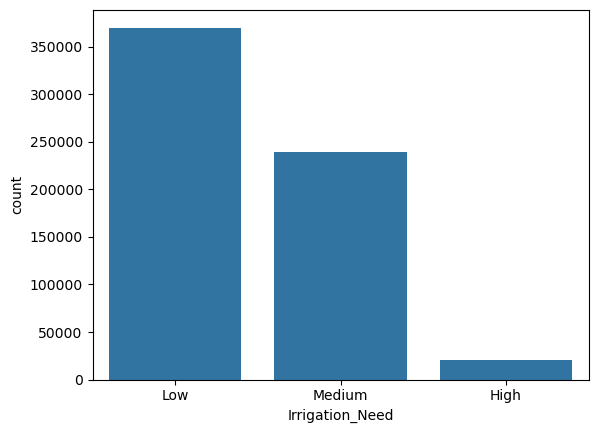

In [10]:
sns.countplot(x='Irrigation_Need', data=train)

<Axes: >

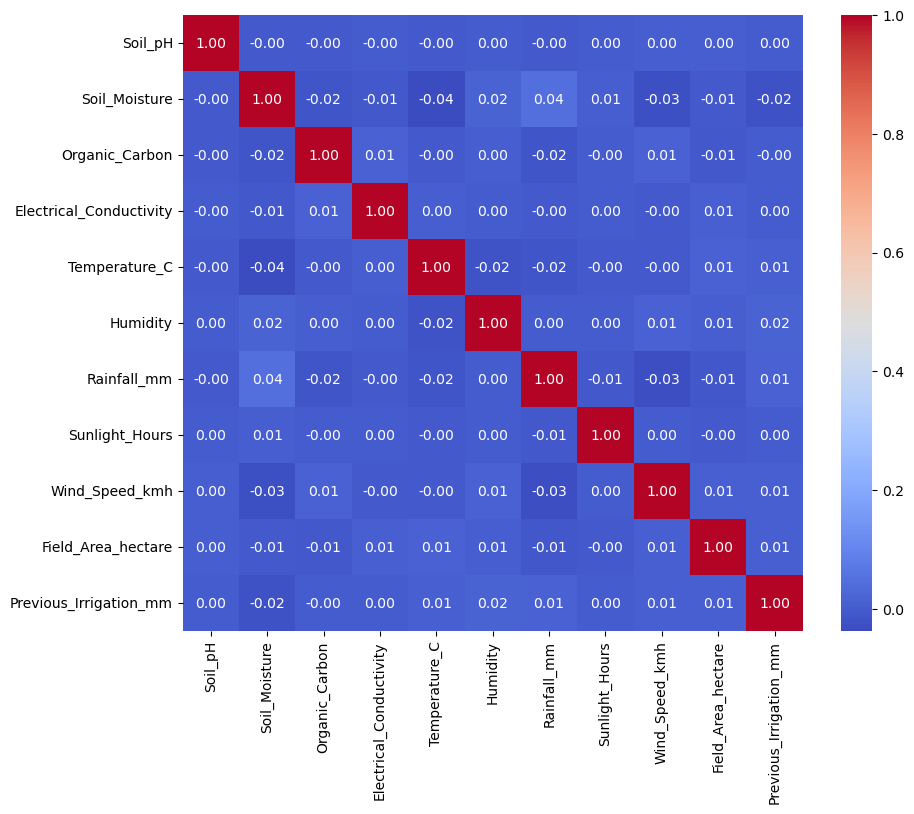

In [11]:
plt.figure(figsize=(10,8))
sns.heatmap(train.drop('id', axis=1).select_dtypes('number').corr(), annot=True, fmt='.2f', cmap='coolwarm')

In [12]:
train['Irrigation_Need'] = train['Irrigation_Need'].map({'Low':0, 'Medium':1, 'High':2})

In [13]:
def ozellik(d):
    d = d.copy()
    d['ET0'] = d['Temperature_C'] * d['Wind_Speed_kmh'] * d['Sunlight_Hours'] / d['Humidity']
    d['Water_Balance'] = d['Rainfall_mm'] + d['Previous_Irrigation_mm'] - d['ET0']
    d['Moisture_Stress'] = d['Temperature_C'] * (100 - d['Humidity']) / d['Soil_Moisture']
    return d.replace([np.inf, -np.inf], 0).fillna(0)

In [14]:
x = ozellik(train.drop(['id','Irrigation_Need'], axis=1))
y = train['Irrigation_Need']
x_test = ozellik(test.drop('id', axis=1))

In [15]:
kat = x.select_dtypes('object').columns.tolist()
say = [c for c in x.columns if c not in kat]
kat

['Soil_Type',
 'Crop_Type',
 'Crop_Growth_Stage',
 'Season',
 'Irrigation_Type',
 'Water_Source',
 'Mulching_Used',
 'Region']

In [16]:
def on():
    return ColumnTransformer([('kat', OneHotEncoder(handle_unknown='ignore'), kat), ('say', StandardScaler(), say)])

In [17]:
x_train, x_val, y_train, y_val = train_test_split(x, y, test_size=.2, random_state=42, stratify=y)

In [18]:
L = make_pipeline(on(), LogisticRegression(max_iter=500, class_weight='balanced'))
L.fit(x_train, y_train)

,steps,"[('columntransformer', ...), ('logisticregression', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('kat', ...), ('say', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [19]:
r = make_pipeline(on(), RandomForestClassifier(n_estimators=100, class_weight='balanced', n_jobs=-1, random_state=42))
r.fit(x_train, y_train)

,steps,"[('columntransformer', ...), ('randomforestclassifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('kat', ...), ('say', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [20]:
b = make_pipeline(on(), HistGradientBoostingClassifier(class_weight='balanced', random_state=42))
b.fit(x_train, y_train)

,steps,"[('columntransformer', ...), ('histgradientboostingclassifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('kat', ...), ('say', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [21]:
karsilastirma = pd.DataFrame({
    'Model': ['LogisticRegression', 'RandomForest', 'HistGradientBoosting'],
    'Balanced Accuracy': [balanced_accuracy_score(y_val, m.predict(x_val)) for m in (L, r, b)]})
karsilastirma

,Model,Balanced Accuracy
0,LogisticRegression,0.853657
1,RandomForest,0.954652
2,HistGradientBoosting,0.967159


In [22]:
tahmin = b.predict(x_val)
print(classification_report(y_val, tahmin, target_names=['Low','Medium','High']))
confusion_matrix(y_val, tahmin)

              precision    recall  f1-score   support

         Low       0.99      0.99      0.99     73983
      Medium       0.98      0.97      0.98     47815
        High       0.89      0.94      0.91      4202

    accuracy                           0.98    126000
   macro avg       0.95      0.97      0.96    126000
weighted avg       0.98      0.98      0.98    126000



array([[73523,   460,     0],
       [ 1047, 46269,   499],
       [    1,   251,  3950]])

In [23]:
model = make_pipeline(on(), HistGradientBoostingClassifier(class_weight='balanced', random_state=42))
model.fit(x, y)

,steps,"[('columntransformer', ...), ('histgradientboostingclassifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('kat', ...), ('say', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [24]:
tahmin = model.predict(x_test)
sonuc = pd.DataFrame({'id': test['id'], 'Irrigation_Need': pd.Series(tahmin).map({0:'Low', 1:'Medium', 2:'High'})})
sonuc.to_csv('sonuc1.csv', index=False)
sonuc.head()

,id,Irrigation_Need
0,630000,Low
1,630001,Low
2,630002,Low
3,630003,Low
4,630004,Low


In [25]:
# Streamlit uygulaması bu iki dosyayı kullanacak
joblib.dump(model, 'irrigation_model.pkl')
train.drop(['id','Irrigation_Need'], axis=1).sample(5000, random_state=42).to_csv('ornek.csv', index=False)

Bu projede tarla, toprak ve hava bilgilerinden sulama ihtiyacını tahmin ettik. Önce EDA ile veriyi tanıdık, sonra su dengesi (ET0, Water_Balance, Moisture_Stress) sütunlarını ürettik ve üç modeli (Logistic Regression, Random Forest, HistGradientBoosting) balanced accuracy ile karşılaştırdık.